In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
#import Keras packages
import os
import matplotlib.pyplot as plt
from PIL import Image
import tensorflow as tf
from tensorflow.keras import layers
from tensorflow.keras import Model
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.utils import img_to_array, load_img, plot_model
import numpy as np

In [3]:
train_dir = r"C:/Users/user/Agrisense Chilli (18062025)/dhenyd/chili-plant-disease/train"
val_dir = r"C:/Users/user/Agrisense Chilli (18062025)/dhenyd/chili-plant-disease/val"
test_dir = r"C:/Users/user/Agrisense Chilli (18062025)/dhenyd/chili-plant-disease/test"

In [4]:
#fitting the dataset
from tensorflow.keras.preprocessing.image import ImageDataGenerator

BATCH_SIZE = 32
IMG_SIZE = (224, 224)

train_datagen = ImageDataGenerator(rescale=1.0/255,
                                   rotation_range=180,
                                   width_shift_range=0.2,
                                   height_shift_range=0.2,
                                   shear_range=0.2,
                                   zoom_range=0.2,
                                   horizontal_flip=True,
                                   fill_mode='nearest'
                                  )

val_test_datagen = ImageDataGenerator(rescale=1.0/255,
                                     )


train_generator = train_datagen.flow_from_directory(train_dir,
                                                    target_size=IMG_SIZE,  # <-- ubah sini
                                                    batch_size=32,
                                                    class_mode='categorical',
                                                    shuffle=True
                                                   )

val_generator = val_test_datagen.flow_from_directory(val_dir,
                                                     target_size=IMG_SIZE,  # <-- ubah sini juga
                                                     batch_size=32,
                                                     class_mode='categorical',
                                                     shuffle=True
                                                    ) 

test_generator = val_test_datagen.flow_from_directory(test_dir,
                                                      target_size=IMG_SIZE,
                                                      class_mode='categorical',
                                                      shuffle=False
                                                     )

Found 400 images belonging to 5 classes.
Found 50 images belonging to 5 classes.
Found 50 images belonging to 5 classes.


In [5]:
model = tf.keras.models.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(224, 224, 3)),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Conv2D(128,(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(2, 2),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(5, activation='softmax')
])

model.summary()

d:\Download\New folder\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │    22,151,424 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 5)              │         1,285 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 22,245,957 (84.86 MB)

 Trainable params: 22,245,957 (84.86 MB)

 Non-trainable params: 0 (0.00 B)

In [6]:
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [7]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)

history = model.fit(
    train_generator,
    validation_data=val_generator,
    epochs=3
)

Epoch 1/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 21s 1s/step - accuracy: 0.1914 - loss: 2.2899 - val_accuracy: 0.2000 - val_loss: 1.5929
Epoch 2/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.2619 - loss: 1.5162 - val_accuracy: 0.2200 - val_loss: 1.8175
Epoch 3/3
13/13 ━━━━━━━━━━━━━━━━━━━━ 18s 1s/step - accuracy: 0.3461 - loss: 1.4258 - val_accuracy: 0.3800 - val_loss: 1.4960


In [8]:
from tensorflow.keras.applications import MobileNetV2

# Load the MobileNetV2 model with pre-trained weights
base_model = MobileNetV2(input_shape=(224, 224, 3), include_top=False, weights='imagenet')

# Freeze the layers of the base model
base_model.trainable = False

# Add a custom classification head
x = base_model.output
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation='relu')(x)
x = layers.Dropout(0.5)(x)
predictions = layers.Dense(5, activation='softmax')(x)  # 5 classes for Chili Disease quality

# Create the transfer learning model
model = Model(inputs=base_model.input, outputs=predictions)

In [9]:
model.compile(optimizer=RMSprop(learning_rate=0.0001),
              loss='categorical_crossentropy',
              metrics=['accuracy'])

In [10]:
history = model.fit(train_generator,
                    validation_data=val_generator,
                    epochs=2
                   )

Epoch 1/2
13/13 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2064 - loss: 2.1680 - val_accuracy: 0.3000 - val_loss: 1.6648
Epoch 2/2
13/13 ━━━━━━━━━━━━━━━━━━━━ 15s 1s/step - accuracy: 0.2968 - loss: 1.7295 - val_accuracy: 0.3400 - val_loss: 1.5447


In [11]:
    _, accuracy = model.evaluate(train_generator)
    _, val_accuracy = model.evaluate(val_generator)

    print('Accuracy {:.2f}%'.format(accuracy * 100))
    print('Val Accuracy {:.2f}%'.format(val_accuracy * 100))

13/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - accuracy: 0.5093 - loss: 1.2262
2/2 ━━━━━━━━━━━━━━━━━━━━ 1s 415ms/step - accuracy: 0.3100 - loss: 1.5709
Accuracy 49.50%
Val Accuracy 34.00%


In [12]:
import os
os.makedirs("C:/Users/user/Agrisense Chilli (18062025)/model", exist_ok=True)

model.save("C:/Users/user/Agrisense Chilli (18062025)/model/testChiliMNV2.keras")
print("Model berjaya disimpan sebagai testChiliMNV2.keras")

Model berjaya disimpan sebagai testChiliMNV2.keras


download (19).jpg
download (6).jpg
whiteflya11.jpg
whiteflya12.jpg
whiteflya13.jpg
whiteflya14.jpg
whiteflya15.jpg
whiteflya16.jpg
whiteflya17.jpg
whiteflya18.jpg
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step


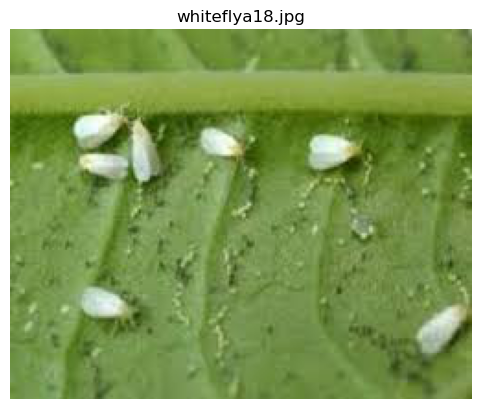


📊 Prediction Scores for All Classes:
healthy: 29.12%
leaf curl: 8.52%
leaf spot: 31.01%
whitefly: 24.98%
yellowish: 6.37%

✅ Predicted Label: leaf spot
🎯 Confidence Score: 31.01 %
----------------------------------------


In [ ]:
import numpy as np
#from google.colab import files
from tensorflow.keras.applications.xception import preprocess_input
from PIL import Image
import matplotlib.pyplot as plt

# Load the trained model from Google Drive
model_path = '/kaggle/working/testChiliMNV2.keras'
model = tf.keras.models.load_model('C:/Users/user/Agrisense Chilli (18062025)/model/testChiliMNV2.keras')

# Define the class labels
class_labels = ["healthy", "leaf curl", "leaf spot", "whitefly",  "yellowish"]

# Function to preprocess and predict on an uploaded image
def preprocess_and_predict(image, filename):
    # Preprocess the image
    img = image.resize((224, 224))
    x = np.array(img)
    x = np.expand_dims(x, axis=0)
    x = preprocess_input(x)

    # Make the prediction
    prediction = model.predict(x)[0]
    predicted_class = np.argmax(prediction)
    class_label = class_labels[predicted_class]
    confidence = prediction[predicted_class]

    # Papar imej
    plt.imshow(image)
    plt.title(f"{filename}")
    plt.axis('off')
    plt.show()

    # Papar semua skor
    print("\n📊 Prediction Scores for All Classes:")
    for i, score in enumerate(prediction):
        print(f"{class_labels[i]}: {round(score * 100, 2)}%")

    # Papar keputusan akhir
    print("\n✅ Predicted Label:", class_label)
    print("🎯 Confidence Score:", round(confidence * 100, 2), "%")
    print("-" * 40)



import os


folder = 'C:/Users/user/Agrisense Chilli (18062025)/dhenyd/chili-plant-disease/test/whitefly'
files = [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.png', '.jpeg'))]

for file in files:
    print(file)

# Ambil fail pertama secara automatik
image_path = os.path.join(folder, file)
img = Image.open(image_path).convert("RGB")

# Panggil fungsi prediction
preprocess_and_predict(img, file)

In [14]:
import tensorflow as tf

# Load the Keras model from the .h5 file
model = tf.keras.models.load_model('C:/Users/user/Agrisense Chilli (18062025)/model/testChiliMNV2.keras')

# Convert the model to TensorFlow Lite format
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

# Save the TensorFlow Lite model to a .tflite file
with open('C:/Users/user/Agrisense Chilli (18062025)/model/testChiliMNV2.tflite', 'wb') as f:
    f.write(tflite_model)

print("Model berjaya ditukar ke .tflite dan disimpan.")

INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpdrumm8y6\assets


INFO:tensorflow:Assets written to: C:\Users\user\AppData\Local\Temp\tmpdrumm8y6\assets


Saved artifact at 'C:\Users\user\AppData\Local\Temp\tmpdrumm8y6'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name='input_layer_1')
Output Type:
  TensorSpec(shape=(None, 5), dtype=tf.float32, name=None)
Captures:
  1386100591120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100590352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100590544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100589776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100588624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100589584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100590160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100589008: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100591312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1386100592464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13861